In [1]:
#Example of supress warnings for Numpy version out of range (optional)
import warnings
warnings.filterwarnings("ignore", category=Warning)

#Pull in the libraries we need
import numpy as np
import pandas as pd

#New libraries for access to model selection tasks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

#Pull in the plotting library and specify to display inline/static images
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
%matplotlib inline

In [2]:
#First step is to load the data into an oject and setup our X and y
fileName = "pet_adoption_data.csv"
petData = pd.read_csv(fileName)

#Select a few of the features and target variable
X = petData[['AgeMonths', 'WeightKg']]
y = petData['AdoptionLikelihood']
X.head()

,AgeMonths,WeightKg
0,131,5.039768
1,73,16.086727
2,136,2.076286
3,97,3.339423
4,123,20.498100


In [3]:
#Split the dataset into training and testing sets with 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
#Standardize the features to have a mean of 0 and a standard deviation of 1 
#Since kNN relies on distance metrics to find the nearest neighbors
#Standardization ensures that no single feature unduly influences the classification
#Could improve accuracy as well as efficiency 
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
X_train

array([[-0.46116564, -0.06302882],
       [ 1.54179462,  1.07271153],
       [ 1.48401692, -0.56989843],
       ...,
       [-1.40486807,  1.50337655],
       [ 1.21438765, -0.20958295],
       [-1.11597957, -0.77389564]])

In [6]:
#Initialize a kNN classifier model object with k=3 and train (or fit) the data
knn_classifier = KNeighborsClassifier(n_neighbors=3)
knn_classifier.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [7]:
#Make predictions
y_pred = knn_classifier.predict(X_test)

#Evaluate the classifier
accuracy = accuracy_score(y_test, y_pred)
print(f"Classification Accuracy: {accuracy:.2f}")

Classification Accuracy: 0.68


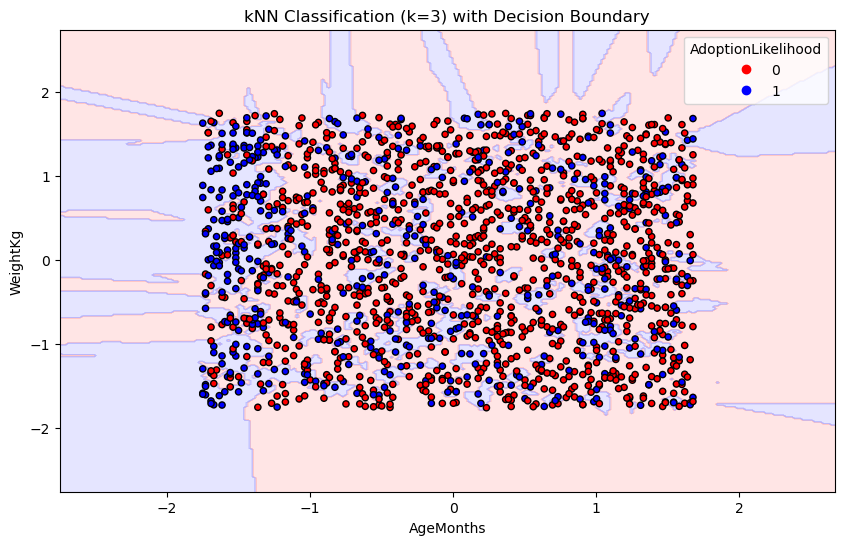

In [8]:
#Create a mesh grid for plotting decision boundaries
h = .02  # step size in the mesh
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

#Predict for each point in the mesh grid
Z = knn_classifier.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Plot the decision boundary and scatter plot
plt.figure(figsize=(10, 6))
cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#0000FF'])
plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)

#Plot the scatter points and add a legend
scatter = plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=20)
plt.xlabel('AgeMonths')
plt.ylabel('WeightKg')
plt.title('kNN Classification (k=3) with Decision Boundary')
plt.legend(*scatter.legend_elements(), title="AdoptionLikelihood")
plt.show()

In [9]:
from sklearn.datasets import load_breast_cancer
#New libraries for access to model selection tasks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix


In [10]:
#First step is to load the data into an oject and setup our X and y
cancerData = load_breast_cancer()
#print(cancerData.DESCR)
X = pd.DataFrame(cancerData.data, columns=cancerData.feature_names)
y = pd.Series(cancerData.target)
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [11]:
#Split the dataset into training and testing sets with 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
#Standardize the features to have a mean of 0 and a standard deviation of 1 
#The SVM can be sensitive to scales of the input features
#Since SVM uses the distance between data points and the dividing line/hyperplane
#Could improve accuracy as well as efficiency 
#Critical if using the RBF (or Gaussian) kernel function
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#Initialize the SVM classifier model object and train (or fit) the data
svm = SVC(kernel='linear')
#svm = SVC(kernel='rbf', C=1, gamma='scale')
svm.fit(X_train, y_train)

#Make predictions
y_pred = svm.predict(X_test)

#Evaluate the classifier
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[41  2]
 [ 3 68]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94        43
           1       0.97      0.96      0.96        71

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



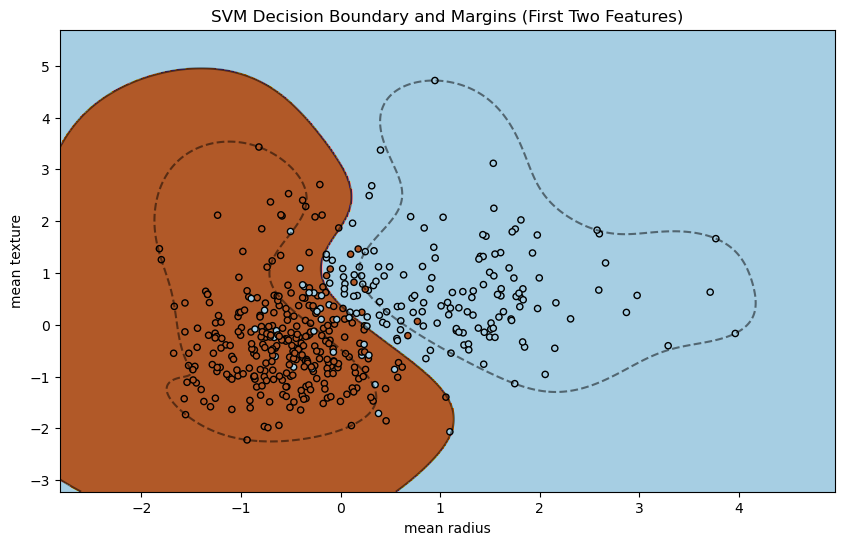

In [16]:
#Visualizing the decision boundary is not straightforward due to high dimensionality
#of the dataset, but here’s an example of a 2D projection (using the first two features)
plt.figure(figsize=(10, 6))

#Use only the first two features for visualization
X_vis = X_train[:, :2]
y_vis = y_train

#Fit the model again with only two features
#svm_vis = SVC(kernel='linear')
svm_vis = SVC(kernel='rbf', C=1, gamma='scale')
svm_vis.fit(X_vis, y_vis)

#Create a mesh to plot the decision boundary
h = .02  # step size in the mesh
x_min, x_max = X_vis[:, 0].min() - 1, X_vis[:, 0].max() + 1
y_min, y_max = X_vis[:, 1].min() - 1, X_vis[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

#Predict classifications for each point in the mesh
Z = svm_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Plot the decision boundary
plt.contourf(xx, yy, Z, color = 'blue', dalpha=0.8, cmap=plt.cm.Paired)

# Plot the margins
Z_decision = svm_vis.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z_decision = Z_decision.reshape(xx.shape)
plt.contour(xx, yy, Z_decision, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

#Plot also the training points
plt.scatter(X_vis[:, 0], X_vis[:, 1], c=y_vis, edgecolors='k', marker='o', s=20, cmap=plt.cm.Paired)
plt.xlabel(cancerData.feature_names[0])
plt.ylabel(cancerData.feature_names[1])
plt.title('SVM Decision Boundary and Margins (First Two Features)')
plt.show()